In [1]:
import pandas as pd

In [2]:
data_train = pd.read_csv('/home/lactea/Documentos/survivor_titanic_predict/data_titanic/titanic/train.csv')
data_test = pd.read_csv('/home/lactea/Documentos/survivor_titanic_predict/data_titanic/titanic/test.csv')

In [3]:
data_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
len(data_train)

891

In [5]:
len(data_test)

418

In [6]:
data_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [7]:
data_test.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [8]:
data_train.rename(columns={
    'PassengerId': 'ID_Passageiro',
    'Survived': 'Sobreviveu',
    'Pclass': 'Classe',
    'Name': 'Nome',
    'Sex': 'Sexo',
    'Age': 'Idade',
    'SibSp': 'Irmaos_Conjuges',
    'Parch': 'Pais_Filhos',
    'Ticket': 'Bilhete',
    'Fare': 'Tarifa',
    'Cabin': 'Cabine',
    'Embarked': 'Embarque'
}, inplace = True)

/tmp/ipykernel_7377/3543048636.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data_train.rename(columns={


In [9]:
data_test.rename(columns={
    'PassengerId': 'ID_Passageiro',
    'Pclass': 'Classe',
    'Name': 'Nome',
    'Sex': 'Sexo',
    'Age': 'Idade',
    'SibSp': 'Irmaos_Conjuges',
    'Parch': 'Pais_Filhos',
    'Ticket': 'Bilhete',
    'Fare': 'Tarifa',
    'Cabin': 'Cabine',
    'Embarked': 'Embarque'
}, inplace = True)

/tmp/ipykernel_7377/2744518593.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data_test.rename(columns={


In [10]:
data_train

,ID_Passageiro,Sobreviveu,Classe,Nome,Sexo,Idade,Irmaos_Conjuges,Pais_Filhos,Bilhete,Tarifa,Cabine,Embarque
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [11]:
len(data_train)

891

In [12]:
len(data_test)

418

In [13]:
data_train.isnull().sum()

ID_Passageiro        0
Sobreviveu           0
Classe               0
Nome                 0
Sexo                 0
Idade              177
Irmaos_Conjuges      0
Pais_Filhos          0
Bilhete              0
Tarifa               0
Cabine             687
Embarque             2
dtype: int64

In [14]:
data_test.isnull().sum()

ID_Passageiro        0
Classe               0
Nome                 0
Sexo                 0
Idade               86
Irmaos_Conjuges      0
Pais_Filhos          0
Bilhete              0
Tarifa               1
Cabine             327
Embarque             0
dtype: int64

In [15]:
data_train.nunique()

ID_Passageiro      891
Sobreviveu           2
Classe               3
Nome               891
Sexo                 2
Idade               88
Irmaos_Conjuges      7
Pais_Filhos          7
Bilhete            681
Tarifa             248
Cabine             147
Embarque             3
dtype: int64

In [16]:
media = data_train['Idade'].mean()
mediana = data_train['Idade'].median()

print(f'Média: {media:.2f}')
print(f'Mediana: {mediana:.2f}')

Média: 29.70
Mediana: 28.00


In [17]:
data_train.groupby('Classe')['Idade'].mean()

Classe
1    38.233441
2    29.877630
3    25.140620
Name: Idade, dtype: float64

In [18]:
data_train.groupby('Classe')['Idade'].median()

Classe
1    37.0
2    29.0
3    24.0
Name: Idade, dtype: float64

In [19]:
import plotly.express as px

fig = px.histogram(
    data_frame=data_train,
    x='Idade',
    nbins=30,
    title='Distribuição das idades - Titanic',
    marginal='box'
)

# Linha da média
fig.add_vline(
    x=media,
    line_dash='dash',
    annotation_text=f'Média: {media:.2f}'
)

# Linha da mediana
fig.add_vline(
    x=mediana,
    line_dash='dot',
    annotation_text=f'Mediana: {mediana:.2f}'
)

fig.show()

In [20]:
fig = px.histogram(
    data_train,
    x='Idade',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por idade',
    text_auto=True
)

fig.show()

In [21]:
fig = px.histogram(
    data_frame=data_train,
    x='Idade',
    nbins=30,
    marginal='box',
    title='Distribuição de idade dos passageiros'
)

fig.show()

In [22]:
data_train = data_train.drop(['ID_Passageiro', 'Nome', 'Bilhete', 'Cabine'], axis=1)
data_test = data_test.drop(['ID_Passageiro', 'Nome', 'Bilhete', 'Cabine'], axis=1)

In [23]:
import numpy as np

np.random.seed(7)

data_train['Idade'] = data_train['Idade'].apply(
    lambda x: np.random.randint(20, 31) if pd.isna(x) else x
)

data_test['Idade'] = data_test['Idade'].apply(
    lambda x: np.random.randint(20, 31) if pd.isna(x) else x
)

In [24]:
data_train['Idade'] = data_train['Idade'].astype(int)

In [25]:
data_test['Idade'] = data_test['Idade'].astype(int)

In [26]:
data_train.head()

,Sobreviveu,Classe,Sexo,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,Embarque
0,0,3,male,22,1,0,7.2500,S
1,1,1,female,38,1,0,71.2833,C
2,1,3,female,26,0,0,7.9250,S
3,1,1,female,35,1,0,53.1000,S
4,0,3,male,35,0,0,8.0500,S


In [27]:
data_train.head()

,Sobreviveu,Classe,Sexo,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,Embarque
0,0,3,male,22,1,0,7.2500,S
1,1,1,female,38,1,0,71.2833,C
2,1,3,female,26,0,0,7.9250,S
3,1,1,female,35,1,0,53.1000,S
4,0,3,male,35,0,0,8.0500,S


In [28]:
data_train['Idade'] = data_train['Idade'].round().astype('Int64')

In [29]:
data_test['Irmaos_Conjuges'] = data_test['Irmaos_Conjuges'].astype(int)
data_test['Pais_Filhos'] = data_test['Pais_Filhos'].astype(int)

In [30]:
data_train['qtd_familiares'] = data_train['Irmaos_Conjuges'] + data_train['Pais_Filhos']
data_test['qtd_familiares'] = data_test['Irmaos_Conjuges'] + data_test['Pais_Filhos']


In [31]:
data_train['qtd_familiares'] = data_train['qtd_familiares'].astype(int)

In [32]:
data_test

,Classe,Sexo,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,Embarque,qtd_familiares
0,3,male,34,0,0,7.8292,Q,0
1,3,female,47,1,0,7.0000,S,1
2,2,male,62,0,0,9.6875,Q,0
3,3,male,27,0,0,8.6625,S,0
4,3,female,22,1,1,12.2875,S,2
...,...,...,...,...,...,...,...,...
413,3,male,27,0,0,8.0500,S,0
414,1,female,39,0,0,108.9000,C,0
415,3,male,38,0,0,7.2500,S,0
416,3,male,25,0,0,8.0500,S,0


In [33]:
fig = px.histogram(
    data_train,
    x='Sobreviveu',
    color='Sobreviveu',
    title='Quantidade de sobreviventes',
    text_auto=True
)

fig.show()

In [34]:
fig = px.histogram(
    data_train,
    x='Sexo',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por sexo',
    text_auto=True
)

fig.show()

In [35]:
fig = px.histogram(
    data_train,
    x='Idade',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por idade',
    text_auto=True
)

fig.show()

In [36]:
fig = px.histogram(
    data_train,
    x='Classe',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por classe',
    text_auto=True
)

fig.show()

In [37]:
fig = px.histogram(
    data_train,
    x='Irmaos_Conjuges',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por qtd de Irmaos/Conjuges',
    text_auto=True
)

fig.show()

In [38]:
fig = px.histogram(
    data_train,
    x='Pais_Filhos',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por qtd de Pais/Filhos',
    text_auto=True
)

fig.show()

In [39]:
fig = px.histogram(
    data_train,
    x='qtd_familiares',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por qtd de Familiares',
    text_auto=True
)

fig.show()

In [40]:
fig = px.histogram(
    data_train,
    x='Embarque',
    color='Sobreviveu',
    barmode='group',
    title='Sobrevivência por local de Embarque',
    text_auto=True
)

fig.show()

In [41]:
data_train.head()

,Sobreviveu,Classe,Sexo,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,Embarque,qtd_familiares
0,0,3,male,22,1,0,7.2500,S,1
1,1,1,female,38,1,0,71.2833,C,1
2,1,3,female,26,0,0,7.9250,S,0
3,1,1,female,35,1,0,53.1000,S,1
4,0,3,male,35,0,0,8.0500,S,0


In [42]:
data_train_encoded = pd.get_dummies(
    data_train,
    columns=['Classe', 'Sexo', 'Embarque'],
    dtype=int
)

In [43]:
data_train_encoded.head()

,Sobreviveu,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male,Embarque_C,Embarque_Q,Embarque_S
0,0,22,1,0,7.2500,1,0,0,1,0,1,0,0,1
1,1,38,1,0,71.2833,1,1,0,0,1,0,1,0,0
2,1,26,0,0,7.9250,0,0,0,1,1,0,0,0,1
3,1,35,1,0,53.1000,1,1,0,0,1,0,0,0,1
4,0,35,0,0,8.0500,0,0,0,1,0,1,0,0,1


In [44]:
data_test['qtd_familiares'].isnull().sum()

np.int64(0)

In [45]:
data_test['qtd_familiares'] = data_test['qtd_familiares'].astype(int)


In [46]:
data_test['Idade'].isnull().sum()

np.int64(0)

In [47]:
data_test['Idade'] = data_test['Idade'].astype(int)

In [48]:
data_test

,Classe,Sexo,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,Embarque,qtd_familiares
0,3,male,34,0,0,7.8292,Q,0
1,3,female,47,1,0,7.0000,S,1
2,2,male,62,0,0,9.6875,Q,0
3,3,male,27,0,0,8.6625,S,0
4,3,female,22,1,1,12.2875,S,2
...,...,...,...,...,...,...,...,...
413,3,male,27,0,0,8.0500,S,0
414,1,female,39,0,0,108.9000,C,0
415,3,male,38,0,0,7.2500,S,0
416,3,male,25,0,0,8.0500,S,0


In [49]:
data_test_encoded = pd.get_dummies(
    data_test,
    columns=['Classe', 'Sexo', 'Embarque'],
    dtype=int
)

In [50]:
data_test_encoded.head()

,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male,Embarque_C,Embarque_Q,Embarque_S
0,34,0,0,7.8292,0,0,0,1,0,1,0,1,0
1,47,1,0,7.0000,1,0,0,1,1,0,0,0,1
2,62,0,0,9.6875,0,0,1,0,0,1,0,1,0
3,27,0,0,8.6625,0,0,0,1,0,1,0,0,1
4,22,1,1,12.2875,2,0,0,1,1,0,0,0,1


In [51]:
from sklearn.model_selection import train_test_split

In [52]:
x = data_train_encoded.drop(columns=['Sobreviveu'])
y = data_train_encoded['Sobreviveu']

In [53]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

In [54]:
from sklearn.tree import DecisionTreeClassifier

In [55]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=7
)

decision_tree_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",7
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [56]:
decision_tree_predict = decision_tree_model.predict(x_test)

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [58]:
print('Acurácia', accuracy_score(y_test, decision_tree_predict))
print('Precisão', precision_score(y_test, decision_tree_predict))
print('Recall', recall_score(y_test, decision_tree_predict))
print('F1-Score', f1_score(y_test, decision_tree_predict))

Acurácia 0.770949720670391
Precisão 0.7
Recall 0.7101449275362319
F1-Score 0.7050359712230215


In [59]:
from sklearn.metrics import confusion_matrix

In [60]:
cm_decision_tree = confusion_matrix(y_test, decision_tree_predict)
print(cm_decision_tree)

[[89 21]
 [20 49]]


In [61]:
from sklearn.metrics import ConfusionMatrixDisplay

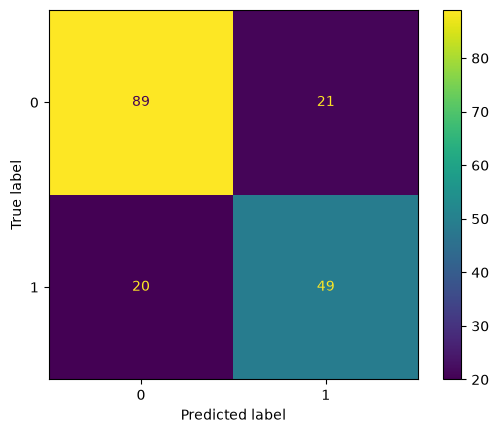

In [62]:
cm_visualizacao_decision_tree = ConfusionMatrixDisplay(confusion_matrix=cm_decision_tree)
cm_visualizacao_decision_tree.plot();

In [63]:
from sklearn.ensemble import RandomForestClassifier

In [64]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
)

random_forest_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [65]:
random_forest_predict = random_forest_model.predict(x_test)

In [66]:
print('Acurácia', accuracy_score(y_test, random_forest_predict))
print('Precisão', precision_score(y_test, random_forest_predict))
print('Recall', recall_score(y_test, random_forest_predict))
print('F1-Score', f1_score(y_test, random_forest_predict))

Acurácia 0.8044692737430168
Precisão 0.7741935483870968
Recall 0.6956521739130435
F1-Score 0.732824427480916


In [67]:
cm_random_forest = confusion_matrix(y_test, random_forest_predict)
print(cm_random_forest)

[[96 14]
 [21 48]]


In [68]:
from xgboost import XGBClassifier

In [69]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=7
)

xgb_model.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [70]:
xgb_predict = xgb_model.predict(x_test)

In [71]:
print('Acurácia', accuracy_score(y_test, xgb_predict))
print('Precisão', precision_score(y_test, xgb_predict))
print('Recall', recall_score(y_test, xgb_predict))
print('F1-Score', f1_score(y_test, xgb_predict))

Acurácia 0.8156424581005587
Precisão 0.78125
Recall 0.7246376811594203
F1-Score 0.7518796992481203


In [72]:
cm_xgboost = confusion_matrix(y_test, xgb_predict)
print(cm_xgboost)

[[96 14]
 [19 50]]


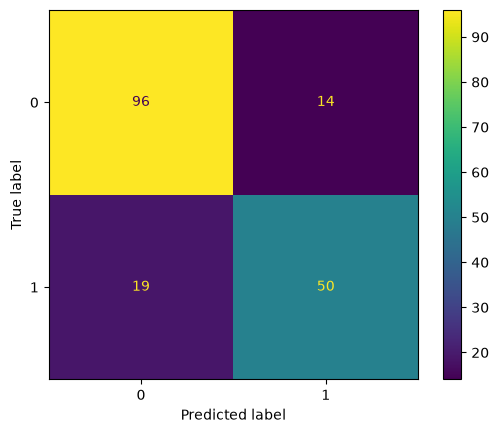

In [73]:
cm_visualizacao_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgboost)
cm_visualizacao_xgb.plot();

In [74]:
data_test_encoded

,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male,Embarque_C,Embarque_Q,Embarque_S
0,34,0,0,7.8292,0,0,0,1,0,1,0,1,0
1,47,1,0,7.0000,1,0,0,1,1,0,0,0,1
2,62,0,0,9.6875,0,0,1,0,0,1,0,1,0
3,27,0,0,8.6625,0,0,0,1,0,1,0,0,1
4,22,1,1,12.2875,2,0,0,1,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,27,0,0,8.0500,0,0,0,1,0,1,0,0,1
414,39,0,0,108.9000,0,1,0,0,1,0,1,0,0
415,38,0,0,7.2500,0,0,0,1,0,1,0,0,1
416,25,0,0,8.0500,0,0,0,1,0,1,0,0,1


In [75]:
data_train_encoded

,Sobreviveu,Idade,Irmaos_Conjuges,Pais_Filhos,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male,Embarque_C,Embarque_Q,Embarque_S
0,0,22,1,0,7.2500,1,0,0,1,0,1,0,0,1
1,1,38,1,0,71.2833,1,1,0,0,1,0,1,0,0
2,1,26,0,0,7.9250,0,0,0,1,1,0,0,0,1
3,1,35,1,0,53.1000,1,1,0,0,1,0,0,0,1
4,0,35,0,0,8.0500,0,0,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,27,0,0,13.0000,0,0,1,0,0,1,0,0,1
887,1,19,0,0,30.0000,0,1,0,0,1,0,0,0,1
888,0,21,1,2,23.4500,3,0,0,1,1,0,0,0,1
889,1,26,0,0,30.0000,0,1,0,0,0,1,1,0,0


In [76]:
survivor_final_predict = xgb_model.predict(data_test_encoded)

In [77]:
survivor_final_predict

array([0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

In [78]:
titanic_survivors = pd.DataFrame(survivor_final_predict, columns=['Survived'])

In [79]:
titanic_survivors

,Survived
0,0
1,0
2,0
3,1
4,1
...,...
413,0
414,1
415,0
416,0


In [80]:
titanic_survivors['PassengerId'] = range(892, 892 + len(titanic_survivors))

In [81]:
titanic_survivors

,Survived,PassengerId
0,0,892
1,0,893
2,0,894
3,1,895
4,1,896
...,...,...
413,0,1305
414,1,1306
415,0,1307
416,0,1308


In [82]:
titanic_survivors.insert(0, 'PassengerId', titanic_survivors.pop('PassengerId'))

In [83]:
titanic_survivors

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [84]:
x_train = x_train[['Idade', 'Tarifa', 'qtd_familiares', 'Classe_1', 'Classe_2', 'Classe_3', 'Sexo_female', 'Sexo_male']]

In [85]:
x_train

,Idade,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male
517,25,24.1500,0,0,0,1,0,1
89,24,8.0500,0,0,0,1,0,1
45,29,8.0500,0,0,0,1,0,1
708,22,151.5500,0,1,0,0,1,0
137,37,53.1000,1,1,0,0,0,1
...,...,...,...,...,...,...,...,...
856,45,164.8667,2,1,0,0,1,0
779,43,211.3375,1,1,0,0,1,0
850,4,31.2750,6,0,0,1,0,1
100,28,7.8958,0,0,0,1,1,0


In [86]:
x_test = x_test[['Idade', 'Tarifa', 'qtd_familiares', 'Classe_1', 'Classe_2', 'Classe_3', 'Sexo_female', 'Sexo_male']]

In [87]:
x_test

,Idade,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male
7,2,21.0750,4,0,0,1,0,1
874,28,24.0000,1,0,1,0,1,0
720,6,33.0000,1,0,1,0,1,0
513,54,59.4000,1,1,0,0,1,0
459,26,7.7500,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...
178,30,13.0000,0,0,1,0,0,1
603,44,8.0500,0,0,0,1,0,1
111,14,14.4542,1,0,0,1,1,0
287,22,7.8958,0,0,0,1,0,1


In [88]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=7
)

xgb_model.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [89]:
xgb_predict = xgb_model.predict(x_test)

In [90]:
print('Acurácia', accuracy_score(y_test, xgb_predict))
print('Precisão', precision_score(y_test, xgb_predict))
print('Recall', recall_score(y_test, xgb_predict))
print('F1-Score', f1_score(y_test, xgb_predict))

Acurácia 0.8324022346368715
Precisão 0.8
Recall 0.7536231884057971
F1-Score 0.7761194029850746


In [91]:
x_train

,Idade,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male
517,25,24.1500,0,0,0,1,0,1
89,24,8.0500,0,0,0,1,0,1
45,29,8.0500,0,0,0,1,0,1
708,22,151.5500,0,1,0,0,1,0
137,37,53.1000,1,1,0,0,0,1
...,...,...,...,...,...,...,...,...
856,45,164.8667,2,1,0,0,1,0
779,43,211.3375,1,1,0,0,1,0
850,4,31.2750,6,0,0,1,0,1
100,28,7.8958,0,0,0,1,1,0


In [92]:
data_test_encoded = data_test_encoded[['Idade', 'Tarifa', 'qtd_familiares', 'Classe_1', 'Classe_2', 'Classe_3', 'Sexo_female', 'Sexo_male']]

In [93]:
data_test_encoded

,Idade,Tarifa,qtd_familiares,Classe_1,Classe_2,Classe_3,Sexo_female,Sexo_male
0,34,7.8292,0,0,0,1,0,1
1,47,7.0000,1,0,0,1,1,0
2,62,9.6875,0,0,1,0,0,1
3,27,8.6625,0,0,0,1,0,1
4,22,12.2875,2,0,0,1,1,0
...,...,...,...,...,...,...,...,...
413,27,8.0500,0,0,0,1,0,1
414,39,108.9000,0,1,0,0,1,0
415,38,7.2500,0,0,0,1,0,1
416,25,8.0500,0,0,0,1,0,1


In [94]:
predicts = xgb_model.predict(data_test_encoded)

In [95]:
df_predict_final = pd.DataFrame(predicts, columns=['Survived'])

In [96]:
df_predict_final['PassengerId'] = range(892, 892 + len(df_predict_final))

In [97]:
df_predict_final

,Survived,PassengerId
0,0,892
1,0,893
2,1,894
3,1,895
4,0,896
...,...,...
413,0,1305
414,1,1306
415,0,1307
416,0,1308


In [98]:
coluna = df_predict_final.pop('PassengerId')
df_predict_final.insert(0, 'PassengerId', coluna)

In [99]:
df_predict_final

,PassengerId,Survived
0,892,0
1,893,0
2,894,1
3,895,1
4,896,0
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [100]:
df_predict_final.to_csv('submission.csv', index=False, encoding='utf-8-sig')

In [101]:
data_train['Sobreviveu'].value_counts(normalize=True) * 100

Sobreviveu
0    61.616162
1    38.383838
Name: proportion, dtype: float64